# Decision Tree vs Linear Regression — Predicting Case Duration

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

The goal is to compare a simple **Decision Tree** regression model with the previous **Linear Regression** baseline
(`02_linear_regression_review.ipynb`).

Linear Regression was better than predicting the mean, but still weak (R² = 0.26), and it predicted a few impossible
negative durations. Can a Decision Tree capture non-linear relationships in the same data better?

- **Target:** `duration_days` (same as before)
- **Features:** `events_per_case`, `unique_activities`, `unique_resources` (same as before)

Using the same features and the same train/test split makes the comparison easier and fairer.

## 2. Load and Prepare Data

Same data and same completed-case logic as the previous notebooks.

In [1]:
import os
import warnings

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
warnings.filterwarnings("ignore")                 # hide an optional speed-up tip from PM4Py

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes("../data/raw/BPIC15_1.xes")
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)

case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data = case_data.reset_index().rename(columns={"case:concept:name": "case_id"})
case_data = case_data[["case_id", "events_per_case", "unique_activities", "unique_resources", "duration_days"]]

print("Completed cases:", len(case_data))
case_data.head()

Completed cases: 956


,case_id,events_per_case,unique_activities,unique_resources,duration_days
0,10009138,45,45,3,55.0
1,10051383,57,56,3,70.0
2,10053042,57,56,3,80.0
3,10093171,46,46,3,79.0
4,10186644,55,54,4,56.0


> **Important limitation:** `events_per_case`, `unique_activities` and `unique_resources` describe the complete finished case.
> Therefore this is still a model-comparison exercise, **not** a valid early-warning model. A future early-warning model
> must use only information available before the case is completed.

## 3. Features and Target

In [3]:
X = case_data[
    [
        "events_per_case",
        "unique_activities",
        "unique_resources"
    ]
]

y = case_data["duration_days"]

## 4. Same Train/Test Split

Exactly the same split as in the Linear Regression notebook (`test_size=0.20`, `random_state=42`), so both models are
tested on the same 192 cases.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 764
Test cases: 192


## 5. Decision Tree Model

A Decision Tree makes predictions by repeatedly **splitting the data into groups** based on feature values.
For example, it may learn rules such as: cases with fewer events go one direction, cases with more events go another
direction. At the end of the tree, each group receives a predicted duration (the average duration of the training cases
in that group).

I use `max_depth=4` only to keep the tree reasonably simple and reduce obvious overfitting.

In [5]:
model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## 6. Evaluate with the Same Metrics

Same definitions as in the Linear Regression notebook:

- **MAE:** on average, how many days the predictions are away from the real values.
- **RMSE:** similar to MAE, but larger mistakes are penalised more.
- **R²:** how much of the variation in case duration is explained by the model.

In [6]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"Decision Tree MAE: {mae:.2f} days")
print(f"Decision Tree RMSE: {rmse:.2f} days")
print(f"Decision Tree R²: {r2:.2f}")

Decision Tree MAE: 58.73 days
Decision Tree RMSE: 125.50 days
Decision Tree R²: 0.27


## 7. Check for Negative Predictions

Linear Regression predicted a few negative durations, which is impossible. A Decision Tree predicts the average duration
of a group of training cases, so its predictions cannot be lower than the shortest training duration.

In [7]:
print(f"Minimum predicted duration: {y_pred.min():.2f} days")
print("Predictions below zero:", (y_pred < 0).sum())

Minimum predicted duration: 62.82 days
Predictions below zero: 0


## 8. Actual vs Predicted

Points on the dashed line would be perfect predictions.

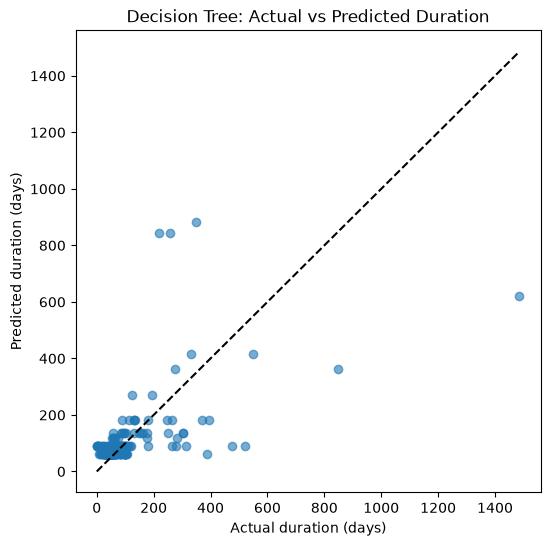

In [8]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], linestyle="--", color="black")
plt.title("Decision Tree: Actual vs Predicted Duration")
plt.xlabel("Actual duration (days)")
plt.ylabel("Predicted duration (days)")
plt.show()

Because a tree gives the same prediction to every case in the same group, the predicted values form a few horizontal
"bands" instead of a smooth line.

## 9. Feature Importance

Feature importance shows which variables the tree used most when making its splits. It does **not** mean that a feature
*causes* longer or shorter cases.

In [9]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})
importance

,feature,importance
0,events_per_case,0.697657
1,unique_activities,0.149111
2,unique_resources,0.153232


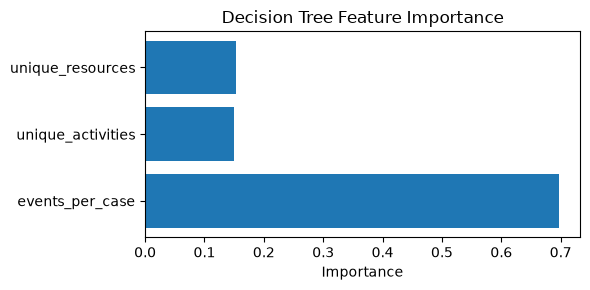

In [10]:
plt.figure(figsize=(6, 3))
plt.barh(importance["feature"], importance["importance"])
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 10. Compare the Three Approaches

- **Mean Baseline:** predict the average training duration for every test case (calculated again here on the same test set).
- **Linear Regression:** results from `02_linear_regression_review.ipynb`.
- **Decision Tree:** results from this notebook.

In [11]:
baseline_pred = [y_train.mean()] * len(y_test)

comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression", "Decision Tree"],
    "MAE": [mean_absolute_error(y_test, baseline_pred), 59.01, mae],
    "RMSE": [mean_squared_error(y_test, baseline_pred) ** 0.5, 126.02, rmse],
    "R²": [r2_score(y_test, baseline_pred), 0.26, r2],
})
comparison.round(2)

,Model,MAE,RMSE,R²
0,Mean Baseline,71.98,147.26,-0.00
1,Linear Regression,59.01,126.02,0.26
2,Decision Tree,58.73,125.50,0.27


## 11. Train vs Test Check

Decision Trees can overfit: they can learn the training data very well but do worse on new data.
If training performance is much better than test performance, the tree may be overfitting.

In [12]:
train_r2 = r2_score(y_train, model.predict(X_train))
test_r2 = r2_score(y_test, y_pred)

print(f"Training R²: {train_r2:.2f}")
print(f"Test R²: {test_r2:.2f}")

Training R²: 0.52
Test R²: 0.27


## 12. Simple Conclusion

1. **Did the Decision Tree beat Linear Regression on MAE?** Only very slightly: 58.73 vs 59.01 days, a difference of
   less than half a day. Both are clearly better than the mean baseline (71.98 days).
2. **Did it improve RMSE?** Only very slightly: 125.50 vs 126.02 days. Large errors on long cases are still a problem.
3. **Did it improve R²?** Only very slightly: 0.27 vs 0.26. Both models explain only about a quarter of the variation in
   case duration. (The mean baseline has R² ≈ 0, as expected for predicting the average.)
4. **Did it avoid negative predictions?** Yes. No prediction is below zero; the lowest prediction is 62.82 days. But this also
   means that the tree predicts at least about 63 days even for very short cases.
5. **Is there evidence of overfitting?** Yes, some. Training R² (0.52) is clearly higher than test R² (0.27). The plot also
   shows a few cases that lasted about 200–350 days but were predicted at about 840–880 days, because they fell into a
   group learned from only a few very long training cases.
6. **Which feature was most important?** `events_per_case` (importance about 0.70). `unique_resources` and
   `unique_activities` were used much less (about 0.15 each).
7. **Is it better enough to justify Random Forest next?** The Decision Tree is **not substantially better** than Linear
   Regression. It mainly fixes the negative predictions. Random Forest is still a reasonable next comparison, because it
   averages many trees and can reduce the overfitting seen here. With only these three features, I should not expect a
   large improvement.

Overall, the Decision Tree gives almost the same result as Linear Regression. With these three features, changing the model
type changes the result very little, so better features will probably matter more than a more complex model.
These features also describe the complete finished case, so this is still a model-comparison exercise, not an early-warning model.

**Next step:** a natural next step is Random Forest, which combines many Decision Trees and may provide more stable predictions.